<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/models/NeuMF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuMF baseline with validation tuning

This notebook implements the **ID-only NeuMF baseline described in the BT4222 report**. Four learned user/article ID embedding tables feed a GMF elementwise-product branch and an MLP branch. Their representations are concatenated to predict a ranking logit. Existing Wikidata vectors and engineered user features are **not baseline inputs**.

Optional, separately labelled **early-fusion and late-fusion extensions** use a compact subset of the unified feature bundle. They do not replace the ID-only benchmark. Optional ID masking compares otherwise matched feature-enhanced models. No RNN, attention or graph-message-passing component is added to this baseline.

The model uses the exact existing chronological preprocessing handoff. It samples four negatives per click from the same training impression and scores every original candidate for validation and test. Validation nDCG@10 controls tuning/checkpoint selection; test evaluation is disabled during development.

Implementation verification for this deliverable: Python syntax and synthetic-fixture tests passed for data alignment, ID/scaler fitting, sampling and ranking metrics. **Neural forward/backward/training execution was not run in the authoring environment because PyTorch was unavailable.** A short automatic model check runs below in Colab before tuning. No full-MIND performance result is claimed.

## 1. Setup and run in Colab

1. Open this notebook in Colab. Select a GPU runtime if available.

2. Before running the setup cell, configure:
   - `STORAGE_ROOT`: the shared project folder in Drive.
   - `PROCESSED_VERSION`: the existing preprocessing version, such as `'v2'`.
   - `FEATURE_VERSION`: the completed feature version for optional fusion, such as `'unified_v1'`.

   Input and output paths are constructed automatically from these settings. `RUN_NAME` generates a timestamped folder for each new study.

3. For the ID-only NeuMF baseline, keep `RUN_FEATURE_FUSION=False`. Leave ID-masking experiments and extra seeds disabled initially.

4. Run the setup cell, allow Drive access and check the printed paths. Then run the remaining cells in order through training, tuning and validation selection.

5. After fixing the model and experiment choices, set `EVALUATE_TEST=True` immediately before running the final evaluation cell. Do not rerun setup just to enable test evaluation. Do not use test results to adjust the model.

### Storage locations

Paths below are relative to `STORAGE_ROOT`, which defaults to `/content/drive/MyDrive/BT4222 Group Project`.

| Purpose | Location |
|---|---|
| Preprocessed inputs | `data/processed/<PROCESSED_VERSION>/` |
| Optional engineered features | `outputs/features/<FEATURE_VERSION>/` |
| Model outputs | `outputs/models/neumf/<RUN_NAME>/` |

The complete preprocessing folder must already exist, including its manifest and train/validation/test `events.csv` and `candidates.csv` files. This notebook does not rebuild preprocessing. No repository ZIP or raw embedding files are required for the ID-only baseline.

### Baseline inputs

The baseline uses `user_id` and `news_id` as categorical inputs and `label` as the training target. It learns its own ID embeddings. Engineered features enter only when feature fusion is enabled.

Event keys, candidate positions and timestamps support alignment, grouped evaluation and split checks; they are not baseline predictors.

In [2]:
from pathlib import Path
import os, sys, json, math, time, random, hashlib, itertools, importlib.util, subprocess
from datetime import datetime, timezone

# Reuse the exact preprocessing handoff used by Unified_Feature_Engineering.ipynb.
MOUNT_GOOGLE_DRIVE = True
PROCESSED_VERSION = 'v2'
FEATURE_VERSION = 'unified_v1'
RUN_NAME = 'neumf_' + datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
N_TRIALS = 12                     # Per model family; includes all 6 dimension/depth pairs.
MAX_EPOCHS = 20
PATIENCE = 3
MIN_DELTA = 1e-4
BATCH_SIZE = 1024
PREDICT_BATCH_SIZE = 16_384
NEGATIVES_PER_CLICK = 4
SEED = 42
TIE_SEED = 2026
RUN_FEATURE_FUSION = False        # Extra early/late studies; not the ID-only baseline.
RUN_ID_MASK_ABLATION = False      # Compare p=0.1 against p=0 for each selected fusion model.
RUN_EXTRA_SEEDS = False           # Repeat selected settings with seeds 43 and 44.
EVALUATE_TEST = False             # Enable only after the full experiment plan is fixed.
SAVE_PREDICTIONS = False          # Full candidate predictions can be large.
USE_ENTITY_VECTOR = True          # One uniform 100-D vector in optional fusion studies.
FEATURE_HISTORY_MODE = 'train_only'

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and MOUNT_GOOGLE_DRIVE and not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive', timeout_ms=300_000)

# Shared storage layout, matching the feature-engineering notebook.
if IN_COLAB:
    STORAGE_ROOT = Path(
        '/content/drive/MyDrive/BT4222 Group Project'
    )
else:
    STORAGE_ROOT = Path(
        os.environ.get('BT4222_PROJECT_ROOT', str(Path.cwd()))
    ).expanduser().resolve()

# Versions are configured at the top of this cell.
PROCESSED_DIR = (
    STORAGE_ROOT / 'data/processed' / PROCESSED_VERSION
)

FEATURE_DIR = (
    STORAGE_ROOT / 'outputs/features' / FEATURE_VERSION
)

RUN_DIR = (
    STORAGE_ROOT / 'outputs/models/neumf' / RUN_NAME
)

print('Preprocessed input:', PROCESSED_DIR)
print('Feature input (optional):', FEATURE_DIR)
print('New model run:', RUN_DIR)

if not (PROCESSED_DIR / 'manifest.json').is_file():
    raise FileNotFoundError(
        f'Preprocessing manifest not found at '
        f'{PROCESSED_DIR / "manifest.json"}. '
        'Check STORAGE_ROOT and PROCESSED_VERSION. '
        'This model notebook requires existing preprocessing outputs; '
        'it does not rebuild them from raw data.'
    )

required = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn', 'torch': 'torch>=2.2'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
try:
    from IPython.display import display
except ImportError:
    display = print

def require(condition, message):
    if not condition:
        raise ValueError(message)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, default=str) + '\n', encoding='utf-8')

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

require(
    (PROCESSED_DIR / 'manifest.json').is_file(),
    'Check STORAGE_ROOT and PROCESSED_VERSION.'
)

require(
    not RUN_DIR.exists(),
    'Choose a new RUN_NAME; existing runs are preserved.'
)


DATA_MANIFEST = json.loads((PROCESSED_DIR / 'manifest.json').read_text())
require(DATA_MANIFEST.get('partitions') == ['train', 'validation', 'test'] and DATA_MANIFEST.get('complete') is True,
        'Use the complete train/validation/test handoff. This notebook does not resplit or rebuild raw data.')
require(1 <= N_TRIALS <= 108 and MAX_EPOCHS >= 1 and PATIENCE >= 1, 'Invalid search/early-stopping settings')
require(NEGATIVES_PER_CLICK >= 1 and BATCH_SIZE >= 1, 'Invalid sampling/batch settings')
require(not RUN_ID_MASK_ABLATION or RUN_FEATURE_FUSION, 'ID masking ablation requires feature fusion.')

for source in [PROCESSED_DIR, FEATURE_DIR]:
    require(RUN_DIR != source and source not in RUN_DIR.parents and RUN_DIR not in source.parents,
            'Keep model outputs separate from preprocessing/features.')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
seed_everything(SEED)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

Mounted at /content/drive
Preprocessed input: /content/drive/MyDrive/BT4222 Group Project/data/processed/v2
Feature input (optional): /content/drive/MyDrive/BT4222 Group Project/outputs/features/unified_v1
New model run: /content/drive/MyDrive/BT4222 Group Project/outputs/models/neumf/neumf_20261107_153214_063090
Device: cuda | PyTorch: 2.14.1+cu130


In [3]:
SOURCE_COMMIT = '6117eeaca6406d2927908944d86649785f483103'
SOURCE_NOTEBOOK_SHA = 'cef5c6a0e2f4bf258b4709ebf8075a28341c5aa7'
SOURCE_SAMPLER_SHA = '3ba9285b1773d881058b1ec18fd116cbe1df6db3'
print('Source snapshot:', SOURCE_COMMIT)

Source snapshot: 6117eeaca6406d2927908944d86649785f483103


## 2 Data and full impression metrics

Training and validation are loaded now. Test labels are not loaded until the final guarded cell. User IDs are fitted on training events, and article IDs on training candidate exposures. Unknown IDs use index 0; validation/test IDs never expand the vocabulary. A separate inference safeguard also maps never-updated ID rows to 0 instead of using random embeddings.

The task is **reranking supplied impression candidates**, not full-catalog retrieval. Report macro AUC, MIND-style MRR, nDCG@5 and nDCG@10 over complete impressions. As in the repository metric helper, all reported ranking metrics use impressions with both clicked and unclicked candidates; excluded impression counts are reported. MIND MRR averages reciprocal ranks of all clicked candidates within each impression, then averages impressions. Ties are broken using a fixed, label-independent random sequence, which matters for cold-start ties.

Do not report sampled-training classification accuracy as the main recommendation metric. The sampled training class ratio is artificial. Sigmoid scores are not calibrated click probabilities without a separate calibration study.

In [4]:
KEYS = ['event_key', 'candidate_position', 'news_id']
EXCLUDED = {'label', 'num_clicked', 'num_unclicked', 'candidate_position', 'group_id', 'slot',
            'event_key', 'impression_id', 'user_id', 'news_id', 'timestamp', 'time'}
INPUT_HASHES = {}

def read_partition(name):
    require(name in ('train', 'validation', 'test'), 'Unknown partition')
    folder = PROCESSED_DIR / name
    events = pd.read_csv(folder / 'events.csv', usecols=['event_key', 'user_id', 'timestamp'],
                         dtype='string', keep_default_na=False)
    events['timestamp'] = pd.to_datetime(events['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='raise')
    candidates = pd.read_csv(folder / 'candidates.csv', usecols=KEYS + ['label'],
        dtype={'event_key': 'string', 'news_id': 'string', 'candidate_position': 'int32', 'label': 'int8'},
        keep_default_na=False)
    require(len(events) > 0 and len(candidates) > 0 and events['event_key'].is_unique, f'{name}: empty/duplicate events')
    require(events['user_id'].str.len().gt(0).all() and events['timestamp'].notna().all(), f'{name}: missing user/time')
    require(not candidates.duplicated(['event_key', 'candidate_position']).any(), f'{name}: repeated candidate keys')
    require(candidates['label'].isin([0, 1]).all(), f'{name}: nonbinary labels')
    event_row = pd.Index(events['event_key']).get_indexer(candidates['event_key'])
    require((event_row >= 0).all() and len(np.unique(event_row)) == len(events), f'{name}: event coverage mismatch')
    require(np.array_equal(candidates.groupby('event_key', sort=False).cumcount().to_numpy(),
                           candidates['candidate_position'].to_numpy()), f'{name}: incomplete candidate positions')
    for path in (folder / 'events.csv', folder / 'candidates.csv'):
        INPUT_HASHES[str(path)] = sha256_file(path)
    return dict(name=name, events=events, candidates=candidates, event_row=event_row,
                numeric=None, categories=None, side_dim=0, category_sizes=[])

def fit_id_vocab(train):
    # IDs are learned lookup keys, not the supplied Wikidata entity embeddings.
    users = sorted(train['events']['user_id'].unique())
    items = sorted(train['candidates']['news_id'].unique())
    return ({v: i + 1 for i, v in enumerate(users)}, {v: i + 1 for i, v in enumerate(items)})

def attach_id_codes(part, users, items):
    part['u'] = part['events']['user_id'].map(users).fillna(0).to_numpy(dtype='int64')[part['event_row']]
    part['i'] = part['candidates']['news_id'].map(items).fillna(0).to_numpy(dtype='int64')
    part['y'] = part['candidates']['label'].to_numpy(dtype='float32')
    part['tie'] = np.random.default_rng(TIE_SEED).random(len(part['y']))
    return part

def ranking_metrics(part, scores, per_impression=False):
    """MIND-style macro metrics, using complete slates and label-independent ties.

    MRR is the mean reciprocal rank of clicked candidates within an impression.
    To match src.feature_diagnostics, all reported metrics use impressions with
    both a click and a non-click. Excluded counts are reported explicitly.
    """
    scores = np.asarray(scores, dtype='float64')
    require(scores.shape == part['y'].shape and np.isfinite(scores).all(), 'Invalid scores')
    data = pd.DataFrame({'g': part['event_row'], 'y': part['y'].astype('int8'), 's': scores, 'tie': part['tie']})
    data = data.sort_values(['g', 's', 'tie'], ascending=[True, False, False], kind='stable')
    data['rank'] = data.groupby('g', sort=False).cumcount() + 1
    data['avg_rank'] = data.groupby('g', sort=False)['s'].rank(method='average', ascending=True)
    group = data.groupby('g', sort=False)
    n, pos = group['y'].size(), group['y'].sum()
    valid = (pos > 0) & (pos < n)
    data['rr'] = data['y'] / data['rank']
    data['gain'] = data['y'] / np.log2(data['rank'] + 1)
    data['pos_rank'] = data['y'] * data['avg_rank']
    sums = data.groupby('g', sort=False).agg(rr=('rr', 'sum'), pr=('pos_rank', 'sum'))
    table = pd.DataFrame({'AUC': (sums['pr'] - pos * (pos + 1) / 2) / (pos * (n - pos)),
                          'MRR': sums['rr'] / pos})
    discount = np.r_[0., np.cumsum(1 / np.log2(np.arange(2, 12)))]
    for k in (5, 10):
        dcg = data.loc[data['rank'].le(k)].groupby('g', sort=False)['gain'].sum().reindex(n.index, fill_value=0.)
        table[f'nDCG@{k}'] = dcg / discount[np.minimum(pos.to_numpy(dtype=int), k)]
    table = table.loc[valid]
    if per_impression:
        return table
    require(len(table) > 0, 'No impressions with both clicked and unclicked candidates for evaluation')
    return {'impressions': int(valid.sum()), 'excluded_impressions': int((~valid).sum()),
            **{k: float(v) for k, v in table.mean().items()}}

train = read_partition('train')
validation = read_partition('validation')
require(train['events']['timestamp'].max() < validation['events']['timestamp'].min(), 'Train/validation chronology overlaps')
require(not set(train['events']['event_key']) & set(validation['events']['event_key']), 'Event keys overlap')
USER_VOCAB, ITEM_VOCAB = fit_id_vocab(train)
attach_id_codes(train, USER_VOCAB, ITEM_VOCAB)
attach_id_codes(validation, USER_VOCAB, ITEM_VOCAB)
print('Training IDs:', len(USER_VOCAB), 'users;', len(ITEM_VOCAB), 'articles; 0 reserved for unknown')
print('Training/validation candidates:', len(train['y']), '/', len(validation['y']))
print('Validation unseen-ID exposure shares:',
      {'user': float((validation['u'] == 0).mean()), 'article': float((validation['i'] == 0).mean())})

Training IDs: 40148 users; 13536 articles; 0 reserved for unknown
Training/validation candidates: 3389342 / 2454102
Validation unseen-ID exposure shares: {'user': 0.24426979807685256, 'article': 0.5033979842728623}


## 3 Training negative sampling

This is the canonical `src/sampling.py` implementation from the pinned repository snapshot, included inline with its `require` import replaced by the identical local helper. Each click forms a group with four same-impression non-clicks. Sampling uses replacement only if there are too few negatives. Impressions without both a positive and a negative contribute no training groups.

Fresh negatives use `seed + epoch`. Repeated sampled rows are retained, including when an impression has multiple clicks. Pointwise BCE consumes rows directly, with one unit of weight per sampled row. Group IDs, slots, labels, original positions and current-impression click totals are excluded from predictor inputs. Candidate keys map samples back to the original rows without multiplying or dropping candidates.

In [5]:
"""Impression-based negative sampling for training; never apply to validation/test.

Compute statistical features (article CTR, popularity, user-category affinity)
on the full train candidates before sampling: sampling fixes the click share
at 1/(k+1), which would inflate any rate computed afterwards. Validation and
test are scored per impression on all candidates (AUC, MRR, nDCG@5/10).
"""
import numpy as np
import pandas as pd


OUTPUT_COLUMNS = ["group_id", "event_key", "news_id", "candidate_position", "label", "slot"]


def sample_negatives(candidates, k=4, seed=0):
    """One group per clicked candidate: the click + k non-clicks from the same impression.

    Slot 0 is the click and slots 1..k are negatives. Use the rows directly for
    pointwise BCE, or group by group_id for a listwise softmax (target slot 0).
    Negatives are drawn without replacement when the impression has at least k,
    otherwise with replacement. Clicks in impressions without negatives are
    dropped. Pass seed=base_seed + epoch to draw fresh negatives each epoch.
    """
    require(k >= 1, "k must be at least 1")
    require(candidates["label"].isin([0, 1]).all(), "Labels must be 0 or 1")
    rng = np.random.default_rng(seed)
    # Sort first so the draw depends only on content and seed, not row order.
    order = ["event_key", "candidate_position"]
    positives = candidates.loc[candidates["label"].eq(1)].sort_values(order, kind="stable")
    negatives = candidates.loc[candidates["label"].eq(0)].sort_values(order, kind="stable").reset_index(drop=True)
    counts = negatives.groupby("event_key", sort=False).size()
    starts = counts.cumsum() - counts

    available = positives["event_key"].map(counts).fillna(0).astype("int64")
    dropped = positives.loc[available.eq(0), "event_key"]
    if len(dropped):
        print(f"Dropped {len(dropped):,} clicks in {dropped.nunique():,} impressions without negatives", flush=True)
    positives = positives.loc[available.gt(0)].reset_index(drop=True)
    n = positives["event_key"].map(counts).to_numpy("int64")[:, None]
    offsets = rng.integers(0, n, size=(len(positives), k))
    # Redraw rows with repeats wherever enough distinct negatives exist.
    while True:
        ordered = np.sort(offsets, axis=1)
        repeated = (ordered[:, 1:] == ordered[:, :-1]).any(axis=1) & (n[:, 0] >= k)
        if not repeated.any():
            break
        offsets[repeated] = rng.integers(0, n[repeated], size=(int(repeated.sum()), k))

    group_ids = np.arange(len(positives), dtype="int64")
    clicked = positives.assign(group_id=group_ids, slot=0)
    picks = (positives["event_key"].map(starts).to_numpy("int64")[:, None] + offsets).ravel()
    skipped = negatives.iloc[picks].assign(
        group_id=np.repeat(group_ids, k), slot=np.tile(np.arange(1, k + 1), len(positives)))
    sampled = pd.concat([clicked, skipped], ignore_index=True)
    sampled["slot"] = sampled["slot"].astype("int8")
    return sampled.sort_values(["group_id", "slot"], kind="stable")[OUTPUT_COLUMNS].reset_index(drop=True)


def training_rows(part, epoch, seed):
    sampled = sample_negatives(part['candidates'], k=NEGATIVES_PER_CLICK, seed=seed + epoch)
    require(len(sampled) > 0, 'No training click has an unclicked candidate in the same impression')
    key = pd.MultiIndex.from_frame(part['candidates'][['event_key', 'candidate_position']])
    idx = key.get_indexer(pd.MultiIndex.from_frame(sampled[['event_key', 'candidate_position']]))
    require((idx >= 0).all(), 'Sampled candidate missing from original slate')
    require(np.array_equal(part['candidates']['news_id'].to_numpy()[idx], sampled['news_id'].to_numpy()),
            'Sampled candidate identity changed')
    require(np.array_equal(part['y'][idx], sampled['label'].to_numpy()), 'Sampled label changed')
    return idx.astype('int64')

## 4 Optional compact feature set

Leave fusion disabled for the report baseline. When enabled, both early and late fusion use the **same** predeclared information:

| Group | Included information |
|---|---|
| Article | Word/entity counts, selected missingness flags, mean/min entity confidence |
| Topic | Separate category and bucketed-subcategory embeddings |
| Knowledge graph | One unit-normalised 100-D **uniform** article entity vector, optional via `USE_ENTITY_VECTOR` |
| User and context | Supplied history length, history category shares, missing-history signals, daily hour sine/cosine |
| Candidate matching | Category/subcategory affinity, one uniform entity cosine, and person/organisation/place overlap/cosine |

Continuous count inputs use log1p, then training-fitted standardisation. Other continuous inputs and the optional entity vector dimensions are standardised using training data too. Categorical IDs enter embedding lookups; they are not scaled as ordinal numbers. Unseen categorical codes and reserved buckets with no training examples map to 0. Train-fitted means, scales and category maps are saved.

Not selected: the four entity-vector alternatives together, raw TF-IDF, weekly effects, historical CTR/popularity columns, or every exported audit flag. This keeps the first feature experiment interpretable. Adding TF-IDF would require a training-fitted sparse projection such as SVD rather than densifying 50,000 columns. Historical CTR or alternative entity schemes can be separate, validation-selected ablations later.

The loader checks the feature/preprocessing manifest match and candidate row alignment. Factorised article/event arrays avoid repeating the whole feature vector across the entire dataset in memory.

In [6]:
# Compact, predeclared feature set for OPTIONAL extensions. These are not baseline inputs.
ARTICLE_NUMERIC = ['title_length', 'abstract_length', 'num_title_entities', 'num_abstract_entities',
    'metadata_missing', 'title_missing', 'abstract_missing', 'entity_conf_mean', 'entity_conf_min',
    'entity_conf_missing', 'entity_vector_missing_uniform']
EVENT_BASE_NUMERIC = ['history_length', 'hour_sin', 'hour_cos', 'history_category_missing',
                      'history_entity_vector_missing_uniform']
CANDIDATE_NUMERIC = ['candidate_history_category_share', 'candidate_history_subcategory_count',
    'candidate_history_subcategory_share', 'entity_similarity_uniform',
    'person_entity_overlap', 'person_embedding_similarity', 'organisation_entity_overlap',
    'organisation_embedding_similarity', 'place_entity_overlap', 'place_embedding_similarity']
COUNT_COLUMNS = {'title_length', 'abstract_length', 'num_title_entities', 'num_abstract_entities',
                 'history_length', 'candidate_history_subcategory_count'}
CATEGORY_EMBEDDING_DIM = 8

class FeaturePipeline:
    """Train-fitted scalers; per-article and per-event arrays stay factorised in memory."""
    def __init__(self):
        require(FEATURE_HISTORY_MODE == 'train_only', 'Use the agreed training-only feedback protocol')
        path = FEATURE_DIR / 'manifest.json'
        require(path.is_file(), 'Optional fusion requires a completed unified feature bundle.')
        self.manifest = json.loads(path.read_text())
        require(self.manifest.get('source_manifest_sha256') == sha256_file(PROCESSED_DIR / 'manifest.json'),
                'Feature bundle and preprocessing manifest do not match.')
        require('train_only' in self.manifest.get('history_features', {}).get('modes', []),
                'Feature bundle does not declare the required train_only protocol')
        self.event_columns = None
        self.scalers = {}
        self.category_maps = []
        self.hashes = {str(path): sha256_file(path)}
        self.side_dim = None

    def _read(self, part):
        folder = FEATURE_DIR / part['name']
        a = pd.read_csv(folder / 'news_features.csv', dtype={'news_id': 'string'}, keep_default_na=False)
        e = pd.read_csv(folder / 'event_features.csv', dtype={'event_key': 'string'}, keep_default_na=False)
        require(a['news_id'].is_unique and e['event_key'].is_unique, 'Feature lookups must be unique')
        erow = pd.Index(e['event_key']).get_indexer(part['events']['event_key'])
        arow = pd.Index(a['news_id']).get_indexer(part['candidates']['news_id'])
        require((erow >= 0).all() and (arow >= 0).all(), 'Feature bundle does not cover this candidate/event set')
        e = e.iloc[erow].reset_index(drop=True)
        if self.event_columns is None:
            self.event_columns = EVENT_BASE_NUMERIC + sorted(c for c in e if c.startswith('history_category_share_'))
        c = pd.read_csv(folder / 'candidate_features.csv.gz', usecols=KEYS + CANDIDATE_NUMERIC,
            dtype={'event_key': 'string', 'news_id': 'string', 'candidate_position': 'int32'}, keep_default_na=False)
        require(c[KEYS].equals(part['candidates'][KEYS]), 'Candidate feature row order/identity differs from source')
        for path in (folder / 'news_features.csv', folder / 'event_features.csv', folder / 'candidate_features.csv.gz'):
            self.hashes[str(path)] = sha256_file(path)
        for name, cols in [('article', ARTICLE_NUMERIC), ('event', self.event_columns), ('candidate', CANDIDATE_NUMERIC)]:
            require(not EXCLUDED.intersection(cols), f'Excluded input selected in {name}')
        raw = {'article': a[ARTICLE_NUMERIC].to_numpy(dtype='float32'),
               'event': e[self.event_columns].to_numpy(dtype='float32'),
               'candidate': c[CANDIDATE_NUMERIC].to_numpy(dtype='float32')}
        for name, cols in [('article', ARTICLE_NUMERIC), ('event', self.event_columns), ('candidate', CANDIDATE_NUMERIC)]:
            for j, column in enumerate(cols):
                if column in COUNT_COLUMNS:
                    require((raw[name][:, j] >= 0).all(), f'Negative count in {column}')
                    raw[name][:, j] = np.log1p(raw[name][:, j])
        if USE_ENTITY_VECTOR:
            index = pd.read_csv(folder / 'news_index.csv', dtype={'news_id': 'string'})
            require(index['news_id'].equals(a['news_id']), 'Entity matrix/news index mismatch')
            with np.load(folder / 'article_entity_vectors.npz', allow_pickle=False) as z:
                vector = z['uniform'].astype('float32')
                require(np.array_equal(z['news_id'], a['news_id'].to_numpy(dtype=str)), 'Entity vector IDs differ')
                require(vector.shape == (len(a), 100), 'Expected one 100-D uniform entity vector per article')
            norm = np.linalg.norm(vector, axis=1, keepdims=True)
            vector = np.divide(vector, norm, out=np.zeros_like(vector), where=norm > 0)
            raw['article'] = np.column_stack([raw['article'], vector]).astype('float32')
            self.hashes[str(folder / 'article_entity_vectors.npz')] = sha256_file(folder / 'article_entity_vectors.npz')
        for name, values in raw.items():
            require(np.isfinite(values).all(), f'Non-finite optional {name} features')
        category_raw = a[['category_id', 'subcategory_id']].to_numpy(dtype='int64')
        return raw, category_raw, arow

    def fit_transform(self, part):
        require(part['name'] == 'train', 'Fit side-feature transforms only on training data')
        raw, cats, arow = self._read(part)
        self.scalers = {name: StandardScaler().fit(values) for name, values in raw.items()}
        # Reserve 0 for unknown AND for reserved buckets with no training examples.
        self.category_maps = [{int(v): j + 1 for j, v in enumerate(sorted(set(cats[:, k]) - {0}))} for k in range(2)]
        self.side_dim = sum(v.shape[1] for v in raw.values())
        return self._attach(part, raw, cats, arow)

    def transform(self, part):
        require(self.scalers, 'Fit training transforms first')
        return self._attach(part, *self._read(part))

    def _attach(self, part, raw, cats, arow):
        side = {name: self.scalers[name].transform(values).astype('float32') for name, values in raw.items()}
        require(sum(v.shape[1] for v in side.values()) == self.side_dim, 'Feature dimension changed')
        codes = np.column_stack([np.array([self.category_maps[k].get(int(v), 0) for v in cats[:, k]],
                                          dtype='int64') for k in range(2)])
        require(all(np.isfinite(v).all() for v in side.values()), 'Non-finite transformed features')
        part['numeric'] = side
        part['categories'] = codes
        part['article_row'] = arow
        part['side_dim'] = self.side_dim
        part['category_sizes'] = [len(m) + 1 for m in self.category_maps]
        return part

    def metadata(self):
        return {'article_columns': ARTICLE_NUMERIC, 'event_columns': self.event_columns,
                'candidate_columns': CANDIDATE_NUMERIC, 'entity_vector': 'uniform' if USE_ENTITY_VECTOR else None,
                'category_maps': self.category_maps, 'category_embedding_dim': CATEGORY_EMBEDDING_DIM,
                'count_transform': 'log1p', 'fit_partition': 'train',
                'scalers': {name: {'mean': s.mean_.tolist(), 'scale': s.scale_.tolist()}
                            for name, s in self.scalers.items()}, 'source_sha256': self.hashes}

FEATURE_PIPELINE = None
if RUN_FEATURE_FUSION:
    FEATURE_PIPELINE = FeaturePipeline()
    FEATURE_PIPELINE.fit_transform(train)
    FEATURE_PIPELINE.transform(validation)
    print('Optional continuous side-feature dimensions:', train['side_dim'])
    print('Optional category vocabulary sizes:', train['category_sizes'])

## 5 Architecture and cold IDs

The baseline is:

$$g_{ui}=p_u^G\odot q_i^G,\qquad m_{ui}=\mathrm{MLP}([p_u^M;q_i^M]),\qquad z_{ui}=w^T[g_{ui};m_{ui}]+b.$$

`BCEWithLogitsLoss` receives the raw logit $z_{ui}$ and binary label. No sigmoid is applied before this loss. Ranking uses logits directly.

| Setting | Where features enter |
|---|---|
| `none` | IDs only; standard GMF plus ID-interaction MLP |
| `early` | Side features and category embeddings are concatenated with the MLP ID embeddings **before** the interaction MLP; GMF stays ID-only |
| `late` | An ID-interaction MLP and a separate side-feature MLP operate independently; GMF and both learned representations are concatenated at the output |

Early/late here refer to **side-feature fusion**. The standard NeuMF combination of GMF and MLP is present in all three variants. Late fusion is representation fusion, not a separately trained score ensemble.

Index 0 has a fixed zero embedding. Unseen users/items and training ID rows never updated by sampling use this deterministic fallback at inference. The ID-only model therefore cannot distinguish two completely new articles by their IDs; this is a meaningful baseline limitation to report.

Optional ID masking hides a user's or article's entire ID embedding in **both** ID branches during training, with probability 0.1. It leaves side features available. This differs from hidden-neuron dropout. Masking alone does not supply information about a new user/article; its cold-start purpose is to train a usable side-feature pathway. The baseline is left unmasked.

In [7]:
def make_mlp(widths, dropout):
    layers = []
    for left, right in zip(widths[:-1], widths[1:]):
        layers += [nn.Linear(left, right), nn.ReLU(), nn.Dropout(dropout)]
    return nn.Sequential(*layers)

class NeuMF(nn.Module):
    def __init__(self, n_users, n_items, embedding_dim=32, hidden=(64, 32), dropout=0.1,
                 fusion='none', side_dim=0, category_sizes=(), id_mask_p=0.0):
        super().__init__()
        require(fusion in ('none', 'early', 'late'), 'Unknown fusion mode')
        require(0 <= id_mask_p < 1, 'ID mask probability must be in [0,1)')
        require(fusion != 'none' or id_mask_p == 0, 'Keep the baseline ID-only with no masking ablation')
        self.fusion, self.id_mask_p = fusion, id_mask_p
        # Four distinct trainable ID tables, as in the NeuMF architecture.
        self.gmf_user = nn.Embedding(n_users, embedding_dim, padding_idx=0)
        self.gmf_item = nn.Embedding(n_items, embedding_dim, padding_idx=0)
        self.mlp_user = nn.Embedding(n_users, embedding_dim, padding_idx=0)
        self.mlp_item = nn.Embedding(n_items, embedding_dim, padding_idx=0)
        self.register_buffer('seen_users', torch.zeros(n_users, dtype=torch.bool))
        self.register_buffer('seen_items', torch.zeros(n_items, dtype=torch.bool))
        self.category_embeddings = nn.ModuleList()
        extra = 0
        if fusion != 'none':
            require(side_dim > 0, 'Fusion requires side features')
            self.category_embeddings = nn.ModuleList([
                nn.Embedding(n, CATEGORY_EMBEDDING_DIM, padding_idx=0) for n in category_sizes])
            extra = side_dim + len(category_sizes) * CATEGORY_EMBEDDING_DIM
        self.id_mlp = make_mlp([2 * embedding_dim + (extra if fusion == 'early' else 0), *hidden], dropout)
        if fusion == 'late':
            self.feature_mlp = make_mlp([extra, *hidden], dropout)
        self.output = nn.Linear(embedding_dim + hidden[-1] * (2 if fusion == 'late' else 1), 1)
        for module in self.modules():
            if isinstance(module, nn.Embedding):
                nn.init.normal_(module.weight, mean=0., std=0.01)
                with torch.no_grad(): module.weight[0].zero_()
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_uniform_(module.weight, nonlinearity='relu')
                nn.init.zeros_(module.bias)
        nn.init.xavier_uniform_(self.output.weight)

    def effective_ids(self, user, item):
        # Unseen or never-updated IDs use deterministic zero vectors, not random rows.
        return (torch.where(self.seen_users[user], user, torch.zeros_like(user)),
                torch.where(self.seen_items[item], item, torch.zeros_like(item)))

    def forward(self, user, item, numeric=None, categories=None):
        if self.training:
            if self.id_mask_p:
                # Hide the same ID in BOTH GMF and MLP tables so neither branch bypasses masking.
                user = user.masked_fill(torch.rand_like(user, dtype=torch.float32) < self.id_mask_p, 0)
                item = item.masked_fill(torch.rand_like(item, dtype=torch.float32) < self.id_mask_p, 0)
            with torch.no_grad():
                self.seen_users[user[user > 0]] = True
                self.seen_items[item[item > 0]] = True
        else:
            user, item = self.effective_ids(user, item)
        gmf = self.gmf_user(user) * self.gmf_item(item)
        ids = torch.cat([self.mlp_user(user), self.mlp_item(item)], dim=1)
        if self.fusion == 'none':
            representation = torch.cat([gmf, self.id_mlp(ids)], dim=1)
        else:
            require(numeric is not None and categories is not None, 'Missing side-feature batch')
            side = torch.cat([numeric, *[embedding(categories[:, j])
                            for j, embedding in enumerate(self.category_embeddings)]], dim=1)
            if self.fusion == 'early':
                representation = torch.cat([gmf, self.id_mlp(torch.cat([ids, side], dim=1))], dim=1)
            else:
                representation = torch.cat([gmf, self.id_mlp(ids), self.feature_mlp(side)], dim=1)
        # Raw logit: BCEWithLogitsLoss applies sigmoid internally during training.
        return self.output(representation).squeeze(-1)

def make_batch(part, rows, fusion):
    u = torch.as_tensor(part['u'][rows], dtype=torch.long, device=DEVICE)
    i = torch.as_tensor(part['i'][rows], dtype=torch.long, device=DEVICE)
    if fusion == 'none':
        return u, i, None, None
    require(part['numeric'] is not None, 'Load optional feature bundle before training fusion models')
    article = part['article_row'][rows]
    event = part['event_row'][rows]
    side = np.column_stack([part['numeric']['article'][article], part['numeric']['event'][event],
                            part['numeric']['candidate'][rows]])
    return u, i, torch.as_tensor(side, device=DEVICE), torch.as_tensor(part['categories'][article], device=DEVICE)

@torch.inference_mode()
def predict(model, part):
    model.eval()
    scores = np.empty(len(part['y']), dtype='float32')
    for start in range(0, len(scores), PREDICT_BATCH_SIZE):
        rows = np.arange(start, min(start + PREDICT_BATCH_SIZE, len(scores)))
        scores[rows] = model(*make_batch(part, rows, model.fusion)).cpu().numpy()
    require(np.isfinite(scores).all(), 'Non-finite prediction scores')
    return scores

## 6 Training and a limited validation search

| Setting | Starting value or search |
|---|---|
| ID embedding dimension | 32; search 16, 32, 64 **in each of the four tables** |
| MLP layers | 64 → 32; compare 64 versus 64 → 32 with ReLU |
| Optimizer | AdamW, starting learning rate 0.001; search 0.0003 and 0.001 |
| Hidden dropout | Starting 0.1; search 0, 0.1, 0.2 |
| Weight decay | Starting 0.00001; search 0.000001, 0.00001, 0.0001 |
| Mini-batch size | Fixed 1024, reduce if needed for your runtime |
| Early stopping | Validation nDCG@10, patience 3, minimum meaningful improvement 0.0001, maximum 20 epochs |
| Search budget | 12 deterministic configurations per enabled family, not the full 108-combination grid |

The search starts with the report configuration and covers every dimension/depth pair among its first six trials. Remaining trials sample the stated grid without replacement. Use comparable trial budgets, sampling and evaluation for advanced models. Log model parameter counts because early/late fusion have different capacities.

Patience 3 allows three consecutive epochs without a meaningful improvement before stopping. It is a starting choice rather than a universal optimum. Every strictly higher validation nDCG checkpoint is saved, and the best checkpoint is restored, even if its improvement was smaller than the patience threshold. No training+validation refit is performed in this initial experiment.

Hidden dropout reduces co-adaptation; AdamW weight decay discourages large weights. AdamW uses decoupled weight decay, so no duplicate manual L2 penalty is added. Biases are not decayed. Mini-batches describe how gradients are estimated; AdamW describes how updates use those gradients, so they are used together. Gradient-norm clipping at 5 is a fixed numerical safeguard.

This is NeuMF trained from scratch with the group's chosen optimizer/regularisation. It is not an exact reproduction of the original paper's full protocol or GMF/MLP pretraining procedure.

In [8]:
BASE_CONFIG = {'embedding_dim': 32, 'hidden': [64, 32], 'learning_rate': 1e-3,
               'dropout': 0.1, 'weight_decay': 1e-5}

def search_configs(n, seed):
    # Begin with the report setting, then cover all embedding-size/depth pairs.
    initial = [dict(BASE_CONFIG)]
    for d, h in itertools.product([16, 32, 64], [[64], [64, 32]]):
        cfg = dict(BASE_CONFIG, embedding_dim=d, hidden=h)
        if cfg not in initial: initial.append(cfg)
    pool = [dict(embedding_dim=d, hidden=h, learning_rate=lr, dropout=drop, weight_decay=wd)
            for d, h, lr, drop, wd in itertools.product(
                [16, 32, 64], [[64], [64, 32]], [3e-4, 1e-3], [0., 0.1, 0.2], [1e-6, 1e-5, 1e-4])]
    remaining = [cfg for cfg in pool if cfg not in initial]
    rng = np.random.default_rng(seed)
    initial += [remaining[j] for j in rng.permutation(len(remaining))]
    return initial[:n]

def model_for(config, fusion, id_mask_p=0.):
    return NeuMF(len(USER_VOCAB) + 1, len(ITEM_VOCAB) + 1,
                 embedding_dim=config['embedding_dim'], hidden=tuple(config['hidden']), dropout=config['dropout'],
                 fusion=fusion, side_dim=train['side_dim'], category_sizes=train['category_sizes'],
                 id_mask_p=id_mask_p).to(DEVICE)

def make_optimizer(model, config):
    # AdamW decoupled weight decay is the selected regularizer; no extra L2 term is added.
    weights, biases = [], []
    for p in model.parameters():
        (weights if p.ndim > 1 else biases).append(p)
    return torch.optim.AdamW([{'params': weights, 'weight_decay': config['weight_decay']},
                               {'params': biases, 'weight_decay': 0.}], lr=config['learning_rate'])

def train_trial(config, fusion, folder, seed=SEED, id_mask_p=0.):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=False)
    seed_everything(seed)
    model = model_for(config, fusion, id_mask_p)
    optimizer = make_optimizer(model, config)
    loss_function = nn.BCEWithLogitsLoss()
    best, patience_best, stale, history = -np.inf, -np.inf, 0, []
    best_epoch, best_metrics = None, None
    tick = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        rows = training_rows(train, epoch, seed)
        # Sampling/shuffling use independent NumPy RNGs, identical across trial configurations.
        rows = rows[np.random.default_rng(seed + 100_000 + epoch).permutation(len(rows))]
        sum_loss = 0.
        for start in range(0, len(rows), BATCH_SIZE):
            batch_rows = rows[start:start + BATCH_SIZE]
            labels = torch.as_tensor(train['y'][batch_rows], device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(*make_batch(train, batch_rows, fusion))
            loss = loss_function(logits, labels)
            require(bool(torch.isfinite(loss)), 'Non-finite training loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5., error_if_nonfinite=True)
            optimizer.step()
            sum_loss += float(loss.detach()) * len(batch_rows)
        # No negative sampling, no optimizer updates and dropout disabled on validation.
        metrics = ranking_metrics(validation, predict(model, validation))
        value = metrics['nDCG@10']
        if value > best:
            best, best_epoch, best_metrics = value, epoch, metrics
            state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
            torch.save({'state_dict': state, 'config': config, 'fusion': fusion,
                        'id_mask_p': id_mask_p, 'seed': seed}, folder / 'best.pt')
        if value > patience_best + MIN_DELTA:
            patience_best, stale = value, 0
        else:
            stale += 1
        history.append({'epoch': epoch, 'train_sampled_bce': sum_loss / len(rows),
                        'sampled_rows': len(rows), 'patience_counter': stale, **metrics})
        pd.DataFrame(history).to_csv(folder / 'learning_curve.csv', index=False)
        print(f'{folder.name} | epoch {epoch:02d} | BCE {sum_loss/len(rows):.4f} | '
              f'val nDCG@10 {value:.4f} | wait {stale}/{PATIENCE}', flush=True)
        if stale >= PATIENCE:
            break
    record = {'trial': folder.name, 'family': fusion, 'seed': seed, 'id_mask_p': id_mask_p,
              'best_epoch': best_epoch, 'epochs_run': len(history),
              'parameters': sum(p.numel() for p in model.parameters()), 'seconds': time.time() - tick,
              'checkpoint': str((folder / 'best.pt').relative_to(RUN_DIR)), **config, **best_metrics}
    write_json(folder / 'result.json', record)
    del model, optimizer
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return record

def load_selected(record):
    saved = torch.load(RUN_DIR / record['checkpoint'], map_location='cpu', weights_only=True)
    model = model_for(saved['config'], saved['fusion'], saved['id_mask_p'])
    model.load_state_dict(saved['state_dict'])
    return model.eval()

def run_study(fusion, configs):
    records = []
    for index, cfg in enumerate(configs):
        print(f'\n{fusion} trial {index+1}/{len(configs)}: {cfg}', flush=True)
        record = train_trial(cfg, fusion, RUN_DIR / fusion / f'trial_{index:02d}')
        records.append(record)
        pd.DataFrame(records).to_csv(RUN_DIR / f'trials_{fusion}.csv', index=False)
    chosen = sorted(records, key=lambda r: (-r['nDCG@10'], r['parameters'], r['trial']))[0]
    write_json(RUN_DIR / f'selected_{fusion}.json', chosen)
    return chosen

def cold_start_report(model, part, scores):
    # Cohort metrics always retain WHOLE impressions, avoiding a smaller candidate pool.
    su = model.seen_users.detach().cpu().numpy()
    si = model.seen_items.detach().cpu().numpy()
    # Define comparable cold cohorts by the SAME training vocabularies for every model.
    cold_u, cold_i = part['u'] == 0, part['i'] == 0
    fallback_u, fallback_i = ~su[part['u']], ~si[part['i']]
    frame = pd.DataFrame({'e': part['event_row'], 'cold_user': cold_u, 'any_cold_item': cold_i})
    events = frame.groupby('e', sort=False).agg(cold_user=('cold_user', 'max'), any_cold_item=('any_cold_item', 'max'))
    table = ranking_metrics(part, scores, per_impression=True)
    events = events.reindex(table.index)
    output = []
    for name, mask in [('all', np.ones(len(table), dtype=bool)),
                       ('warm_user', ~events['cold_user']), ('cold_user', events['cold_user']),
                       ('all_items_warm', ~events['any_cold_item']), ('any_cold_item', events['any_cold_item'])]:
        subset = table.loc[np.asarray(mask)]
        output.append({'cohort': name, 'impressions': len(subset),
                       **{k: float(v) for k, v in subset.mean().items()}})
    return {'cold_user_exposure_share': float(cold_u.mean()), 'cold_item_exposure_share': float(cold_i.mean()),
            'zero_user_fallback_share': float(fallback_u.mean()), 'zero_item_fallback_share': float(fallback_i.mean())}, pd.DataFrame(output)

## 7 Quick checks before spending tuning time

The broader repository test suite and manual feature audit can be done later during development. Keep these small checks enabled now: train-only IDs, sampling alignment, the multi-click metric definition, cold fallback, model output shapes, backpropagation through both ID branches, and deterministic evaluation with dropout disabled. These checks do not train a model on the full dataset.

In [9]:
def run_minimum_checks():
    # Correct multi-click MIND MRR, full-slate ordering and AUC tied-score handling.
    fixture = {'y': np.array([1, 0, 1], dtype='float32'), 'event_row': np.array([0, 0, 0]),
               'tie': np.array([0.2, 0.3, 0.1])}
    metrics = ranking_metrics(fixture, np.array([3., 2., 1.]))
    np.testing.assert_allclose(metrics['MRR'], (1. + 1./3.) / 2.)
    np.testing.assert_allclose(metrics['AUC'], 0.5)
    np.testing.assert_allclose(ranking_metrics(fixture, np.zeros(3))['AUC'], 0.5)
    require(USER_VOCAB == {v: i+1 for i, v in enumerate(sorted(train['events']['user_id'].unique()))},
            'User IDs were not fitted on training only')
    require(ITEM_VOCAB == {v: i+1 for i, v in enumerate(sorted(train['candidates']['news_id'].unique()))},
            'Article IDs were not fitted on training exposures only')
    sample = sample_negatives(pd.DataFrame({
        'event_key': ['e'] * 3, 'candidate_position': [0, 1, 2], 'news_id': ['N1', 'N2', 'N3'], 'label': [1, 0, 0]}),
        k=4, seed=7)
    require(len(sample) == 5 and sample['label'].sum() == 1 and sample['news_id'].iloc[0] == 'N1',
            'Sampling did not preserve the click plus four same-impression negatives')
    require(sample['news_id'].iloc[1:].isin(['N2', 'N3']).all(), 'Sampling selected an invalid negative')
    for fusion in ('none', 'early', 'late'):
        seed_everything(SEED)
        model = NeuMF(4, 5, embedding_dim=4, hidden=(8, 4), dropout=0.2,
                      fusion=fusion, side_dim=3, category_sizes=(3, 4), id_mask_p=0.)
        u, i = torch.tensor([1, 2]), torch.tensor([2, 3])
        side = torch.randn(2, 3)
        cats = torch.tensor([[1, 2], [2, 3]])
        model.train()
        out = model(u, i, side, cats)
        require(tuple(out.shape) == (2,) and bool(torch.isfinite(out).all()), f'{fusion}: wrong output shape')
        nn.BCEWithLogitsLoss()(out, torch.tensor([1., 0.])).backward()
        require(model.gmf_user.weight.grad is not None and model.mlp_item.weight.grad is not None,
                'Both ID branches must participate in backpropagation')
        model.eval()
        a, b = model(u, i, side, cats), model(u, i, side, cats)
        torch.testing.assert_close(a, b)
        z_u, z_i = model.effective_ids(torch.tensor([0, 3]), torch.tensor([0, 4]))
        require(bool((z_u == 0).all() and (z_i == 0).all()), 'Unknown/untrained IDs were not mapped to 0')
        for embedding in [model.gmf_user, model.gmf_item, model.mlp_user, model.mlp_item]:
            require(bool((embedding.weight[0] == 0).all()), 'Unknown-ID embedding is not zero')
    rows = training_rows(train, epoch=1, seed=SEED)
    require(len(rows) % (NEGATIVES_PER_CLICK + 1) == 0, 'Training sample group sizes are inconsistent')
    if RUN_FEATURE_FUSION:
        require(FEATURE_PIPELINE is not None and FEATURE_PIPELINE.side_dim > 0, 'Feature transforms missing')
    print('Minimum checks passed: train-only IDs, sampler alignment, MIND metrics, all model shapes/gradients, '
          'dropout evaluation mode and cold-ID fallback.')

run_minimum_checks()

Minimum checks passed: train-only IDs, sampler alignment, MIND metrics, all model shapes/gradients, dropout evaluation mode and cold-ID fallback.


## 8 Run model selection

The default runs only the ID-only study. `RUN_FEATURE_FUSION=True` adds two equal-budget early/late studies with the compact feature set. Do not call the resulting hybrid models the ID-only baseline.

`RUN_ID_MASK_ABLATION=True` additionally retrains the selected early/late configurations with mask probability 0.1, holding their other settings and seed fixed. Compare each against its unmasked version. `RUN_EXTRA_SEEDS=True` repeats selected settings with seeds 43 and 44; report mean and standard deviation rather than choosing the best seed. These options increase compute.

Each trial records its sampled BCE curve, full-slate validation metrics, best epoch, runtime, parameter count and checkpoint. Checkpoints include the effective trained-ID flags. Vocabulary maps and feature transforms stay with the run folder. Test labels remain unread throughout selection.

In [10]:
# Only training/validation files have been loaded at this point.
RUN_DIR.mkdir(parents=True, exist_ok=False)
write_json(RUN_DIR / 'user_vocab.json', USER_VOCAB)
write_json(RUN_DIR / 'item_vocab.json', ITEM_VOCAB)
CONFIGS = search_configs(N_TRIALS, SEED)
write_json(RUN_DIR / 'search_configs.json', CONFIGS)
pd.DataFrame(CONFIGS).to_csv(RUN_DIR / 'search_configs.csv', index=False)
if FEATURE_PIPELINE is not None:
    write_json(RUN_DIR / 'feature_transforms.json', FEATURE_PIPELINE.metadata())

SELECTED_MODELS = {'baseline': run_study('none', CONFIGS)}
if RUN_FEATURE_FUSION:
    SELECTED_MODELS['early'] = run_study('early', CONFIGS)
    SELECTED_MODELS['late'] = run_study('late', CONFIGS)
    if RUN_ID_MASK_ABLATION:
        for family in ('early', 'late'):
            chosen = SELECTED_MODELS[family]
            cfg = {key: chosen[key] for key in BASE_CONFIG}
            # Same configuration and seed; only ID masking changes in this comparison.
            SELECTED_MODELS[family + '_idmask010'] = train_trial(
                cfg, family, RUN_DIR / (family + '_idmask010'), id_mask_p=0.1)

if RUN_EXTRA_SEEDS:
    for label, selected in list(SELECTED_MODELS.items()):
        cfg = {key: selected[key] for key in BASE_CONFIG}
        for repeat_seed in (43, 44):
            SELECTED_MODELS[f'{label}_seed{repeat_seed}'] = train_trial(
                cfg, selected['family'], RUN_DIR / f'{label}_seed{repeat_seed}', seed=repeat_seed,
                id_mask_p=selected['id_mask_p'])

for label, selected in SELECTED_MODELS.items():
    model = load_selected(selected)
    scores = predict(model, validation)
    metrics = ranking_metrics(validation, scores)
    np.testing.assert_allclose(metrics['nDCG@10'], selected['nDCG@10'], atol=1e-7)
    cold, cohorts = cold_start_report(model, validation, scores)
    write_json(RUN_DIR / f'validation_{label}.json', {**metrics, **cold})
    cohorts.to_csv(RUN_DIR / f'validation_cohorts_{label}.csv', index=False)
    if SAVE_PREDICTIONS:
        validation['candidates'].assign(ranking_score=scores).to_csv(
            RUN_DIR / f'validation_predictions_{label}.csv.gz', index=False, compression='gzip')
    del model

selection = {'selection_metric': 'validation nDCG@10', 'models': SELECTED_MODELS,
             'fit_partition': 'train', 'test_used_for_selection': False}
write_json(RUN_DIR / 'selection_locked.json', selection)
write_json(RUN_DIR / 'run_manifest.json', {
    'pipeline': 'BT4222 NeuMF baseline and optional side-feature studies',
    'source_repository': 'JariusF10-8/bt4222', 'source_commit': SOURCE_COMMIT,
    'source_unified_notebook_sha': SOURCE_NOTEBOOK_SHA,
    'processed_manifest_sha256': sha256_file(PROCESSED_DIR / 'manifest.json'),
    'input_sha256': INPUT_HASHES, 'processed_directory': str(PROCESSED_DIR),
    'feature_directory': str(FEATURE_DIR) if RUN_FEATURE_FUSION else None,
    'feature_transforms': FEATURE_PIPELINE.metadata() if FEATURE_PIPELINE is not None else None,
    'id_vocab_fit': 'training exposures/events only', 'unknown_id': 0,
    'unknown_policy': 'fixed zero ID vectors; never-updated training IDs also use zero at inference',
    'negative_sampling': {'k': NEGATIVES_PER_CLICK, 'source': 'same complete training impression',
                          'refresh': 'each epoch, seed + epoch', 'pointwise_weighting': 'one sampled row per BCE example'},
    'evaluation': {'candidate_pool': 'complete original impression', 'tie_seed': TIE_SEED,
                  'metric_impressions': 'at least one click and one non-click; excluded groups reported',
                  'MRR': 'mean reciprocal rank of clicked candidates, then mean over impressions'},
    'training': {'optimizer': 'AdamW', 'weight_decay': 'decoupled; no additional L2 penalty',
                 'bias_decay': 0, 'loss': 'BCEWithLogitsLoss', 'batch_size': BATCH_SIZE,
                 'gradient_clip_norm': 5, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
                 'min_delta': MIN_DELTA, 'seed': SEED, 'trials_per_family': N_TRIALS,
                 'families': ['ID-only'] + (['early', 'late'] if RUN_FEATURE_FUSION else []),
                 'parameter_initialization': 'normal(0,0.01) embeddings; Kaiming MLP; Xavier output',
                 'GMF_MLP_pretraining': False},
    'test_labels_read': False,
    'libraries': {'python': sys.version, 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__},
    'device': str(DEVICE), 'created_at_utc': datetime.now(timezone.utc).isoformat()})
summary = pd.DataFrame([{'model': name, **record} for name, record in SELECTED_MODELS.items()])
summary.to_csv(RUN_DIR / 'selected_validation_results.csv', index=False)
if RUN_EXTRA_SEEDS:
    repeated = summary.assign(setting=summary['model'].str.replace(r'_seed\d+$', '', regex=True))
    repeated.groupby('setting')[['AUC', 'MRR', 'nDCG@5', 'nDCG@10']].agg(['mean', 'std', 'count']).to_csv(
        RUN_DIR / 'selected_validation_seed_summary.csv')
display(summary[['model', 'embedding_dim', 'hidden', 'dropout', 'learning_rate', 'weight_decay',
                 'id_mask_p', 'best_epoch', 'parameters', 'AUC', 'MRR', 'nDCG@5', 'nDCG@10']])
print('Completed model selection without reading test labels:', RUN_DIR)


none trial 1/12: {'embedding_dim': 32, 'hidden': [64, 32], 'learning_rate': 0.001, 'dropout': 0.1, 'weight_decay': 1e-05}
trial_00 | epoch 01 | BCE 0.4734 | val nDCG@10 0.2960 | wait 0/3
trial_00 | epoch 02 | BCE 0.4223 | val nDCG@10 0.2989 | wait 0/3
trial_00 | epoch 03 | BCE 0.3515 | val nDCG@10 0.2969 | wait 1/3
trial_00 | epoch 04 | BCE 0.2792 | val nDCG@10 0.2924 | wait 2/3
trial_00 | epoch 05 | BCE 0.2206 | val nDCG@10 0.2896 | wait 3/3

none trial 2/12: {'embedding_dim': 16, 'hidden': [64], 'learning_rate': 0.001, 'dropout': 0.1, 'weight_decay': 1e-05}
trial_01 | epoch 01 | BCE 0.4801 | val nDCG@10 0.2958 | wait 0/3
trial_01 | epoch 02 | BCE 0.4336 | val nDCG@10 0.2985 | wait 0/3
trial_01 | epoch 03 | BCE 0.3842 | val nDCG@10 0.2973 | wait 1/3
trial_01 | epoch 04 | BCE 0.3348 | val nDCG@10 0.2934 | wait 2/3
trial_01 | epoch 05 | BCE 0.2931 | val nDCG@10 0.2917 | wait 3/3

none trial 3/12: {'embedding_dim': 16, 'hidden': [64, 32], 'learning_rate': 0.001, 'dropout': 0.1, 'weight_

,model,embedding_dim,hidden,dropout,learning_rate,weight_decay,id_mask_p,best_epoch,parameters,AUC,MRR,nDCG@5,nDCG@10
0,baseline,16,"[64, 32]",0.2,0.001,0.0001,0.0,2,1722193,0.544865,0.23285,0.240818,0.299299


Completed model selection without reading test labels: /content/drive/MyDrive/BT4222 Group Project/outputs/models/neumf/neumf_20261107_153214_063090


In [11]:
baseline_model = load_selected(SELECTED_MODELS['baseline'])

train_metrics = ranking_metrics(
    train, predict(baseline_model, train)
)

train_results = pd.DataFrame([
    {'model': 'baseline', 'seed': SEED, **train_metrics}
])
display(train_results)
train_results.to_csv(RUN_DIR / 'train_results.csv', index=False)

del baseline_model

,model,seed,impressions,excluded_impressions,AUC,MRR,nDCG@5,nDCG@10
0,baseline,42,95071,0,0.802729,0.477427,0.518467,0.564944


## 9 Inspect the selected baseline curve

The two panels show different quantities: optimisation of the sampled BCE objective and generalisation on the actual validation candidate slates. Falling training loss with stagnant or falling validation ranking quality is a reason to stop, rather than simply train for more epochs.

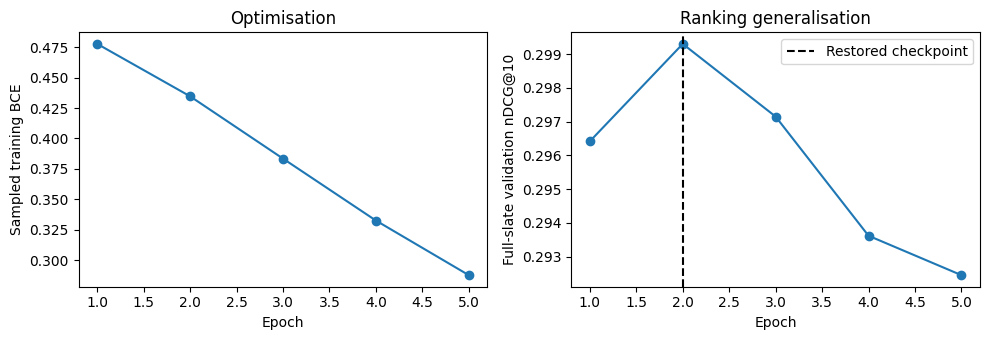

In [12]:
if importlib.util.find_spec('matplotlib') is not None:
    import matplotlib.pyplot as plt
    curve = pd.read_csv(
        (RUN_DIR / SELECTED_MODELS['baseline']['checkpoint']).parent / 'learning_curve.csv')
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(curve['epoch'], curve['train_sampled_bce'], marker='o')
    axes[0].set(xlabel='Epoch', ylabel='Sampled training BCE', title='Optimisation')
    axes[1].plot(curve['epoch'], curve['nDCG@10'], marker='o')
    axes[1].axvline(SELECTED_MODELS['baseline']['best_epoch'], color='black', linestyle='--', label='Restored checkpoint')
    axes[1].set(xlabel='Epoch', ylabel='Full-slate validation nDCG@10', title='Ranking generalisation')
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'baseline_learning_curves.png', dpi=160)
    plt.show()

## 10 Final held-out evaluation

Keep `EVALUATE_TEST=False` while deciding features, fusion, regularisation and hyperparameters. Once the complete comparison is fixed, set it to `True` in a small cell immediately before this cell. This evaluates only locked validation-selected checkpoints; it does not fit test statistics or change mappings. It does not select a winner using test results.

Cold cohorts are defined by the same train-only ID vocabularies across all models. Cohort metrics retain **whole impressions**; they do not remove cold candidates and thereby shrink the ranking pool. Zero-fallback shares additionally include ID rows that were never updated during training. Empty cohorts have no metric estimate. A completion marker prevents accidental repeated test evaluation within this run.

In [13]:
# Run Test Evaluation Code

EVALUATE_TEST = True
SAVE_PREDICTIONS = True  # Set True if you also want candidate-level scores.

print('Existing run folder:', RUN_DIR)
print('Models to evaluate:', list(SELECTED_MODELS))

Existing run folder: /content/drive/MyDrive/BT4222 Group Project/outputs/models/neumf/neumf_20261107_153214_063090
Models to evaluate: ['baseline']


In [14]:
# Set EVALUATE_TEST = True here only after fixing model families, features,
# tuning budget and configurations for the final comparison.
if not EVALUATE_TEST:
    print('Test evaluation skipped. Keep test outcomes held out during development.')
else:
    require(not (RUN_DIR / 'test_evaluation_complete.json').exists(),
            'This run already evaluated test. Reuse its saved metrics rather than selecting settings on test.')
    locked = json.loads((RUN_DIR / 'selection_locked.json').read_text())
    require(locked['models'] == json.loads(json.dumps(SELECTED_MODELS)), 'Selected models differ from the locked settings')
    test = read_partition('test')
    require(validation['events']['timestamp'].max() < test['events']['timestamp'].min(), 'Validation/test chronology overlaps')
    require(not set(test['events']['event_key']) & (set(train['events']['event_key']) | set(validation['events']['event_key'])),
            'Test event keys overlap earlier partitions')
    attach_id_codes(test, USER_VOCAB, ITEM_VOCAB)
    if FEATURE_PIPELINE is not None:
        FEATURE_PIPELINE.transform(test)
    records = []
    for name, record in SELECTED_MODELS.items():
        model = load_selected(record)
        scores = predict(model, test)
        metrics = ranking_metrics(test, scores)
        cold, cohorts = cold_start_report(model, test, scores)
        records.append({'model': name, 'seed': record['seed'], **metrics, **cold})
        cohorts.to_csv(RUN_DIR / f'test_cohorts_{name}.csv', index=False)
        if SAVE_PREDICTIONS:
            test['candidates'].assign(ranking_score=scores).to_csv(
                RUN_DIR / f'test_predictions_{name}.csv.gz', index=False, compression='gzip')
        del model
    pd.DataFrame(records).to_csv(RUN_DIR / 'test_results.csv', index=False)
    write_json(RUN_DIR / 'test_evaluation_complete.json', {'models': list(SELECTED_MODELS),
        'input_sha256': INPUT_HASHES, 'metrics': records, 'timestamp_utc': datetime.now(timezone.utc).isoformat()})
    display(pd.DataFrame(records))
    print('Final test results saved. Do not revise hyperparameters in response to these results.')

,model,seed,impressions,excluded_impressions,AUC,MRR,nDCG@5,nDCG@10,cold_user_exposure_share,cold_item_exposure_share,zero_user_fallback_share,zero_item_fallback_share
0,baseline,42,73152,0,0.509509,0.222333,0.227515,0.291194,0.897433,0.8979,0.897433,0.914881


Final test results saved. Do not revise hyperparameters in response to these results.


## 11 Outputs and report guidance

Keep the complete timestamped run folder together:

- `search_configs.*`, `trials_<family>.csv` and per-trial `learning_curve.csv`: tuning decisions and optimisation history.
- Per-trial `best.pt`: model weights and configuration. The selected checkpoint path is stored relative to the run folder.
- `user_vocab.json`, `item_vocab.json`, optional `feature_transforms.json`: training-fitted input transforms.
- `selected_<family>.json`, `selection_locked.json`, `selected_validation_results.csv`: selected configurations and validation evidence.
- `validation_cohorts_*.csv`, optional `test_cohorts_*.csv`: whole-impression cold-start breakdowns.
- `run_manifest.json`: source snapshot, input hashes, libraries, protocol and defaults. Test evaluation, when explicitly enabled, writes a separate completion record and test results.
- Optional full-candidate prediction files include labels for evaluation; labels are never predictor inputs. Predictions retain the original candidate keys and ordering.

This is a **ID-based neural benchmark**. A baseline is a comparison reference, not necessarily a non-neural or weak model. Keep content-based and history-aware advanced models distinct. ID-only NeuMF's cold-article limitation is particularly relevant in a chronological news task; report it rather than hiding cold candidates or building vocabularies from test interactions.

The compact feature extensions can support ablations about side information and fusion. They do not establish that every engineered feature helps. Use train/validation to select feature families. Preserve the baseline's absence of explicit history/content inputs to keep the report comparison meaningful.

## References and lecture alignment

- He et al., Neural Collaborative Filtering, WWW 2017, sections 3.2–3.4 and 4.1: https://arxiv.org/abs/1708.05031 . This notebook uses the NeuMF architecture with a MIND impression protocol, not the paper's leave-one-out benchmark protocol.
- Provided **Lecture 6 Embedding**, slides 49–53: standard NeuMF, early/late side-feature fusion and ID masking.
- Provided **Lecture 5 Deep Neural Networks**, slides 57–62: overfitting, early stopping on validation and dropout.
- Provided **Lecture 3 Optimization**, slides 22–24 and 39–40: mini-batch gradients and regularisation. Use validation, not final test, for early stopping in this project.
- Provided **Lecture 2 Representation**, slide 26: scaling continuous features; fit transform parameters on training only.
- Provided **Lecture 4 Evaluation**, slides 32–38: ranking metrics and candidate-pool sensitivity. Here the agreed task is reranking complete MIND impression slates.
- Provided Lectures 7–9 discuss sequence, attention and graph models; they motivate separate advanced comparisons rather than extra components required in this baseline.
- PyTorch BCEWithLogitsLoss: https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html
- PyTorch AdamW: https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html
- PyTorch Dropout: https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html